# Demand Forecasting - walkthrough (Project 3)

## 1. Learning objectives
After this notebook you can:
1. Build **lag and rolling features** per product-store series without leaking tomorrow's sales into today's row.
2. Evaluate a forecast with a **chronological split** and with **WAPE / bias** (and explain why MAPE breaks on zero-sales days).
3. Show why a **tree model cannot extrapolate** to a new demand level, while a log-linear model follows it better.
4. Read a **KS drift test** correctly - drift is a *signal*, not an automatic reason to retrain.
5. Produce a **7-day batch forecast** with the same feature code that the real-time API uses.

Course map: DATA -> FEATURE ENGINEERING -> TRAINING -> (MLflow) -> REGISTRY -> DEPLOYMENT -> MONITORING -> DRIFT -> RETRAINING.
This notebook covers the first half and previews the second half; the scripts in `src/` do the production version.

## 2. Business problem
A retailer sells 8 products in 3 stores. At the **end of day D** the planner needs **units for day D+1** per product-store
(replenishment) and for the next 7 days (weekly planning).

| Error | Business meaning |
|---|---|
| Forecast too high (over-forecast) | stock waste / holding cost |
| Forecast too low (under-forecast) | lost sales, unhappy customers (we weight it 3x in our cost example) |

It is a **regression** problem (target = `sales`, a count of units) - not a classification problem.

## 3. Dataset description
`data/raw/sales_daily.csv`: 2 years (2023-2024), one row per product x store x day (24 series, 17,544 rows), **fully synthetic**
(see `docs/DATASET.md`). Problems injected on purpose: weekly + annual seasonality, trend, holidays, promotions, price effects,
stock-out zeros, bulk-order outliers, POS outage days (missing sales), weather-service outages (missing forecast_temp).

| Known in advance for the forecast day | NOT known at forecast time |
|---|---|
| calendar, holiday, planned price/discount/promotion, weather **forecast** | **sales** of that day, **actual** temperature |

Rule to repeat all semester: *"Would this information be available at prediction time?"*

## 4. Why this concept is needed
Time series rows are **not independent**. Tomorrow looks like today. Two consequences:
* the best features are *recent history* (lags, rolling means) - but they must stop at **yesterday**;
* the validation split must also respect time (train on the past, test on the future) - never shuffle.

In [1]:
## 5. Imports
import os, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # works from the project root or from notebooks/
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from src.common.params import load_params
from src.features.build_features import compute_features, features_for_batch, training_frame
from src.features.history_store import HistoryStore
from src.features.leakage_demo import fit_score, fit_scores, light
from src.features.manual_examples import toy_frame
from src.features.select_features import load_selected
from src.common.drift import ks_drift_report
from src.models import metrics as M
from src.models.baselines import BASELINES, baseline_forecast
from src.models.batch_forecast import recursive_forecast
from src.models.pipelines import build_pipeline
from src.models.train import score, time_split

pd.set_option("display.width", 140)
print("project root:", ROOT.name)

project root: demand-forecast


In [2]:
## 6. Load data  (generated by `python -m src.data.make_dataset`; created here if missing)
if not (ROOT / "data/raw/sales_daily.csv").exists():
    from src.data.make_dataset import write_all
    write_all()
raw = pd.read_csv("data/raw/sales_daily.csv", parse_dates=["date"])
print(raw.shape, "| series:", raw.groupby(["product_id", "store_id"]).ngroups, "| days:", raw["date"].nunique())
raw.head(3)

(17544, 11) | series: 24 | days: 731


        date product_id store_id  sales  price  discount  promotion  holiday  temperature  forecast_temp  day_of_week
0 2023-01-01        P01       S1  158.0   45.0       0.0          0        1         15.5           15.2            6
1 2023-01-01        P01       S2  157.0   45.0       0.0          0        1         24.7           21.3            6
2 2023-01-01        P01       S3   89.0   45.0       0.0          0        1         21.1            NaN            6

missing sales (POS outage): 0.46% | missing forecast_temp: 1.50% | zero-sales days: 42

average daily sales per series, weekly (training: last 4 weeks | drifted production: all 8 full weeks)
training_last4  127.0  115.0  127.0  107.0
production  151.0  142.0  148.0  157.0  169.0  170.0  178.0  182.0


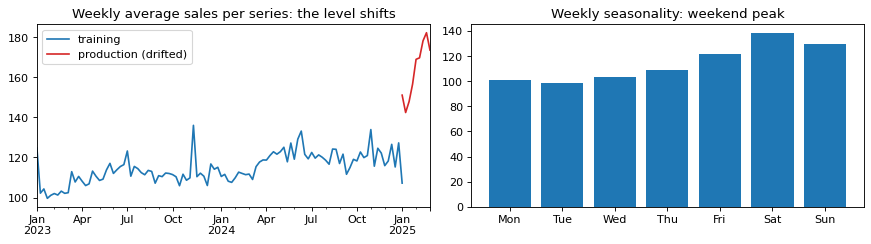

In [3]:
## 7. Explore data: missingness, zero days, and the level of the business
print("missing sales (POS outage):", f"{raw.sales.isna().mean():.2%}", "| missing forecast_temp:", f"{raw.forecast_temp.isna().mean():.2%}",
      "| zero-sales days:", int((raw.sales == 0).sum()))
batch_drifted = pd.read_csv("data/production/batch_drifted.csv", parse_dates=["forecast_date"])
weekly = lambda s: s.groupby(s.index.to_period("W-SUN")).mean()
tr_week = weekly(raw.groupby("date")["sales"].mean())
pr_week = weekly(batch_drifted.groupby("forecast_date")["sales"].mean())
print("\naverage daily sales per series, weekly (training: last 4 weeks | drifted production: all 8 full weeks)")
print(pd.DataFrame({"training_last4": tr_week.tail(4).round(0).values}).T.to_string(header=False))
print(pd.DataFrame({"production": pr_week.iloc[:8].round(0).values}).T.to_string(header=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
tr_week.plot(ax=ax[0], label="training"); pr_week.plot(ax=ax[0], label="production (drifted)", color="tab:red")
ax[0].set_title("Weekly average sales per series: the level shifts"); ax[0].legend(); ax[0].set_xlabel("")
dow = raw.groupby(raw.date.dt.dayofweek)["sales"].mean()
ax[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.values); ax[1].set_title("Weekly seasonality: weekend peak")
plt.tight_layout(); plt.show()

In [4]:
## 8. Baselines first: three forecasts that need no learning
df = training_frame(raw)                                   # engineered frame (lags etc.), warm-up rows removed
params = load_params()
train, valid, test = time_split(df, params["split"])        # chronological: train < valid < test
print({k: (str(v.date.min().date()), str(v.date.max().date()), len(v)) for k, v in dict(train=train, valid=valid, test=test).items()})
rows = []
for name in BASELINES:
    f = baseline_forecast(name, test)
    rows.append(dict(model=name, wape=M.wape(test.sales, f), bias_pct=M.bias_pct(test.sales, f), mae=M.mae(test.sales, f)))
base = pd.DataFrame(rows).set_index("model").round(4)
base

{'train': ('2023-01-31', '2024-06-30', 12336), 'valid': ('2024-07-01', '2024-09-30', 2200), 'test': ('2024-10-01', '2024-12-31', 2208)}


                    wape  bias_pct      mae
model                                      
naive             0.1944   -0.0005  23.6363
seasonal_naive    0.2077   -0.0053  25.2505
moving_average_7  0.1864    0.0001  22.6634

## 9. Concept: lags and rolling means - and the one rule that matters
```
day:      1   2   3   4   5   6   7   8
sales:   10  12  11  13  20  22  21  14
                                      ^ we forecast day 8 at the end of day 7
rolling_mean_7 for day 8 must use days 1..7  (not day 8!)
```
In pandas: `sales.shift(1).rolling(7).mean()` - **shift first, then roll**. `rolling(7)` alone includes *today*.

In [5]:
## 10. Manual calculation vs code
s = np.array([10, 12, 11, 13, 20, 22, 21, 14], float)
by_hand_correct = s[0:7].mean()          # days 1..7  -> what is known at the end of day 7
by_hand_leaky   = s[1:8].mean()          # days 2..8  -> includes the day we want to predict
print(f"by hand : correct = mean(10,12,11,13,20,22,21) = {by_hand_correct:.2f} | leaky (includes day 8) = {by_hand_leaky:.2f}")
f = compute_features(toy_frame())        # our real feature function on the same 8 days
print(f"code    : rolling_mean_7 on day 8 = {f.iloc[7].rolling_mean_7:.2f} | lag_1 = {f.iloc[7].lag_1:.0f} | lag_7 = {f.iloc[7].lag_7:.0f}")
assert abs(f.iloc[7].rolling_mean_7 - by_hand_correct) < 1e-9

by hand : correct = mean(10,12,11,13,20,22,21) = 15.57 | leaky (includes day 8) = 16.14
code    : rolling_mean_7 on day 8 = 15.57 | lag_1 = 21 | lag_7 = 10


In [6]:
## 11. Python implementation: the same function builds features for training, batch and the API
cols = ["date", "sales", "lag_1", "lag_7", "rolling_mean_7", "dow_sin", "dow_cos"]
print(compute_features(toy_frame()).loc[:, cols].round(3).to_string(index=False))

# ONLINE vs OFFLINE parity: a history store (stand-in for an online feature store) must give the SAME numbers as training
store = HistoryStore(raw[["date", "product_id", "store_id", "sales", "price", "discount", "promotion", "holiday", "forecast_temp"]])
r = raw[(raw.product_id == "P04") & (raw.store_id == "S2") & (raw.date == "2024-12-10")].iloc[0]
online = store.features_for("P04", "S2", "2024-12-10", r.price, r.discount, int(r.promotion), int(r.holiday), r.forecast_temp).iloc[0]
offline = df[(df.product_id == "P04") & (df.store_id == "S2") & (df.date == "2024-12-10")].iloc[0]
for c in ["lag_1", "lag_7", "rolling_mean_7", "rolling_mean_30"]:
    print(f"{c:<16} offline={offline[c]:9.3f}  online={online[c]:9.3f}")

      date  sales  lag_1  lag_7  rolling_mean_7  dow_sin  dow_cos
2025-01-01   10.0    NaN    NaN             NaN    0.975   -0.223
2025-01-02   12.0   10.0    NaN             NaN    0.434   -0.901
2025-01-03   11.0   12.0    NaN             NaN   -0.434   -0.901
2025-01-04   13.0   11.0    NaN             NaN   -0.975   -0.223
2025-01-05   20.0   13.0 11.500          11.500   -0.782    0.623
2025-01-06   22.0   20.0 13.200          13.200    0.000    1.000
2025-01-07   21.0   22.0 14.667          14.667    0.782    0.623
2025-01-08   14.0   21.0 10.000          15.571    0.975   -0.223
lag_1            offline=  224.000  online=  224.000
lag_7            offline=  177.000  online=  177.000
rolling_mean_7   offline=  205.571  online=  205.571
rolling_mean_30  offline=  201.733  online=  201.733


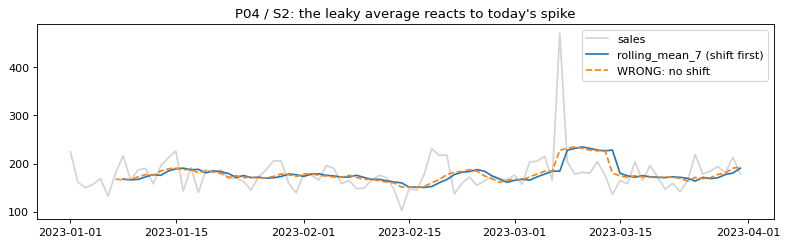

In [7]:
## 12. Visualization: correct vs leaky rolling mean on one series
one = raw[(raw.product_id == "P04") & (raw.store_id == "S2")].sort_values("date").head(90).reset_index(drop=True)
ok = one.sales.shift(1).rolling(7).mean()      # correct: days t-7..t-1
leaky = one.sales.rolling(7).mean()            # WRONG: days t-6..t (contains today's sales)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(one.date, one.sales, color="lightgray", label="sales"); ax.plot(one.date, ok, label="rolling_mean_7 (shift first)")
ax.plot(one.date, leaky, "--", label="WRONG: no shift"); ax.legend(); ax.set_title("P04 / S2: the leaky average reacts to today's spike")
plt.tight_layout(); plt.show()

In [8]:
## 13. Model implementation: selected features, Ridge (log) vs gradient boosting - fitted on TRAIN only
feats = load_selected()                                      # chosen on training rows only (see docs/sample_outputs/03_feature_selection.txt)
print(len(feats), "features:", feats)
p = light(params)                                            # 100-tree boosting so the notebook runs in seconds
models = {k: build_pipeline(k, feats, p).fit(train[feats], train["sales"]) for k in ("ridge_log", "hgb")}
rows = []
for k, pipe in models.items():
    f = score(pipe, test, feats)
    rows.append(dict(model=k, wape=M.wape(test.sales, f), bias_pct=M.bias_pct(test.sales, f), mae=M.mae(test.sales, f)))
res = pd.concat([base, pd.DataFrame(rows).set_index("model").round(4)])
res

14 features: ['product_id', 'store_id', 'day_of_week', 'is_holiday', 'month_sin', 'month_cos', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'discount_pct', 'price_change', 'promotion_flag', 'forecast_temp']


                    wape  bias_pct      mae
model                                      
naive             0.1944   -0.0005  23.6363
seasonal_naive    0.2077   -0.0053  25.2505
moving_average_7  0.1864    0.0001  22.6634
ridge_log         0.1320   -0.0180  16.0434
hgb               0.1286   -0.0201  15.6267

In [9]:
## 14. Evaluation in business language
best = res.wape.idxmin()
print(f"best on the TEST period: {best}  (WAPE {res.loc[best, 'wape']:.3f} = {res.loc[best, 'wape']:.1%} of units sold are 'wrong')")
f = score(models["hgb"], test, feats)
cost = M.cost_report(test.sales, f, over=1.0, under=3.0)
print("units over-forecast (waste risk):", cost["over_forecast_units"], "| under-forecast (lost-sales risk):", cost["under_forecast_units"])
# why not MAPE?  one stock-out day makes the percentage error explode
y, fc = np.array([100., 0., 50.]), np.array([90., 10., 55.])
print("MAPE with a zero-sales day:", M.mape_naive(y, fc), "| WAPE:", round(M.wape(y, fc), 3))

best on the TEST period: hgb  (WAPE 0.129 = 12.9% of units sold are 'wrong')
units over-forecast (waste risk): 14550 | under-forecast (lost-sales risk): 19953
MAPE with a zero-sales day: inf | WAPE: 0.167


            wape  bias_pct
model                     
ridge_log  0.138    -0.089
hgb        0.200    -0.155
Tree leaves store AVERAGES of training targets -> forecasts cannot exceed what was seen. A linear model on log(lags) follows the level better.


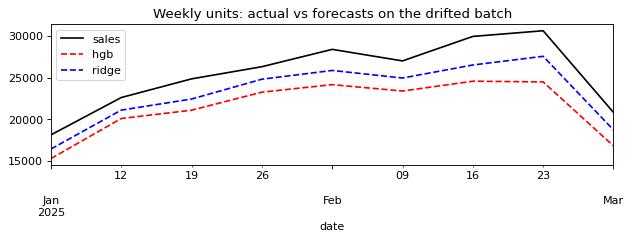

In [10]:
## 15. Interpretation: the level shifts to a range never seen in training (150 -> 210)
fb = features_for_batch(batch_drifted, raw); fb = fb[fb.sales.notna()]
rows = []
for k, pipe in models.items():
    f = score(pipe, fb, feats)
    rows.append(dict(model=k, wape=M.wape(fb.sales, f), bias_pct=M.bias_pct(fb.sales, f)))
shift = pd.DataFrame(rows).set_index("model").round(3)
print(shift)
fb = fb.assign(hgb=score(models["hgb"], fb, feats), ridge=score(models["ridge_log"], fb, feats))
w = fb.groupby(pd.to_datetime(fb.date).dt.to_period("W-SUN"))[["sales", "hgb", "ridge"]].sum()
fig, ax = plt.subplots(figsize=(8, 3.2)); w.plot(ax=ax, style=["k-", "r--", "b--"]); ax.set_title("Weekly units: actual vs forecasts on the drifted batch"); plt.tight_layout(); plt.show()
print("Tree leaves store AVERAGES of training targets -> forecasts cannot exceed what was seen. A linear model on log(lags) follows the level better.")

In [11]:
## 16. Drift is a signal, not a command: KS test on lag / rolling features
ref = pd.read_csv("data/processed/reference.csv")
fb2 = features_for_batch(batch_drifted, raw); fb2 = fb2[fb2.sales.notna()]
rep = ks_drift_report(ref, fb2, ["lag_1", "rolling_mean_7", "price", "discount_pct"])
print("H0: reference and production come from the same distribution; alpha = 0.05; practical threshold D >= 0.10")
print(rep[["feature", "ks_statistic", "p_value", "status"]].to_string(index=False))
print(f"\nDid the boosting model fail? WAPE on the drifted batch = {shift.loc['hgb', 'wape']:.3f} vs {res.loc['hgb', 'wape']:.3f} on the test period; bias {shift.loc['hgb', 'bias_pct']:+.1%}.")
print("Here drift AND a labelled-performance drop agree. Compare with the festival batch (docs/sample_outputs/11b...): inputs drift, accuracy holds.")
print("Rule of the project: retrain only when drift AND labelled performance (WAPE/bias) say so - then compare champion vs challenger on the same hold-out.")

H0: reference and production come from the same distribution; alpha = 0.05; practical threshold D >= 0.10
       feature  ks_statistic      p_value               status
         lag_1        0.2397 1.093698e-55                drift
rolling_mean_7        0.2632 3.690432e-67                drift
         price        0.2133 4.648410e-44                drift
  discount_pct        0.0291 3.043893e-01 no_evidence_of_drift

Did the boosting model fail? WAPE on the drifted batch = 0.200 vs 0.129 on the test period; bias -15.5%.
Here drift AND a labelled-performance drop agree. Compare with the festival batch (docs/sample_outputs/11b...): inputs drift, accuracy holds.
Rule of the project: retrain only when drift AND labelled performance (WAPE/bias) say so - then compare champion vs challenger on the same hold-out.


In [12]:
## 17. Common mistake: random split vs chronological split (honest numbers)
rnd = [fit_scores(df.iloc[idx[:cut]], df.iloc[idx[cut:]], feats, p)
       for idx, cut in [(np.random.default_rng(sd).permutation(len(df)), int(0.8 * len(df))) for sd in range(2)]]
tim = fit_scores(pd.concat([train, valid]), test, feats, p)
print(f"shuffled 80/20 split : WAPE {np.mean([r['wape'] for r in rnd]):.4f}   MAE {np.mean([r['mae'] for r in rnd]):.2f}")
print(f"chronological split  : WAPE {tim['wape']:.4f}   MAE {tim['mae']:.2f}")
from src.features.leakage_demo import label_in_training_features
print(f"share of test labels that already sit inside TRAINING features after the random split: {label_in_training_features(df):.0%}")
print("The WAPE gap is small for this model (lags carry most of the signal), yet 99% of the answers leaked. Larger leaks: see")
print("docs/sample_outputs/04_leakage_demo.txt (centred / un-shifted rolling windows cut the error by 14-33% - an impossible result).")

shuffled 80/20 split : WAPE 0.1280   MAE 14.66
chronological split  : WAPE 0.1292   MAE 15.70
share of test labels that already sit inside TRAINING features after the random split: 99%
The WAPE gap is small for this model (lags carry most of the signal), yet 99% of the answers leaked. Larger leaks: see
docs/sample_outputs/04_leakage_demo.txt (centred / un-shifted rolling windows cut the error by 14-33% - an impossible result).


In [13]:
## 18. Industry connection: weekly BATCH forecast with the same features (recursive, 7 days)
art = dict(pipeline=models["hgb"], input_columns=feats, extra=dict(interval=dict(low=-0.2, high=0.2)))
hist = raw[["date", "product_id", "store_id", "sales", "price", "discount", "promotion", "holiday", "forecast_temp"]]
fc = recursive_forecast(hist, art, pd.Timestamp("2024-12-31"), horizon=7)
print(f"{len(fc)} rows = 24 series x 7 days; forecast made at the END of 2024-12-31 (only data <= that day)")
fc[(fc.product_id == "P04") & (fc.store_id == "S2")][["forecast_date", "horizon", "predicted_units", "lower", "upper"]]

168 rows = 24 series x 7 days; forecast made at the END of 2024-12-31 (only data <= that day)


    forecast_date  horizon  predicted_units  lower  upper
10     2025-01-01        1            190.9  152.7  229.0
34     2025-01-02        2            181.8  130.3  233.2
58     2025-01-03        3            197.6  129.1  266.0
82     2025-01-04        4            203.3  122.0  284.6
106    2025-01-05        5            196.3  108.5  284.1
130    2025-01-06        6            160.4   81.8  238.9
154    2025-01-07        7            169.2   79.7  258.8

## 19. Common mistakes (checklist)
* `rolling(7)` without `shift(1)` -> today's sales inside today's feature.
* Centered windows (`center=True`) -> the future inside the feature.
* Random `train_test_split` on time series; scaler fitted on all data.
* Using the **actual** temperature instead of the **forecast** temperature.
* MAPE with zero-sales days; duplicated dates after a pipeline retry; price units that change silently.
* "Drift detected, retrain now!" - first check data quality, then labelled performance, then business impact.

## 20. Exercises
1. Add `lag_28` and `rolling_mean_14`. Do they pass the registry gate? (Hint: add them to `configs/feature_registry.yaml` first.)
2. Change `max_iter` of the boosting model. How do WAPE and bias on the *drifted* batch change?
3. Compute WAPE per product on the test period. Which product is hardest? Why (promotions? holidays?)?
4. Re-run section 15 with `center=True` features and explain the (unrealistically good) result.
5. Simulate a 3-day stale history store (`docs/sample_outputs/13_failure_scenarios.txt`) and describe what an alert should say.

## 21. Key takeaways
* Features stop at **yesterday**: `shift(1)` before `rolling`.
* Split by **time**. Report **WAPE and bias**, not MAPE.
* Trees cannot extrapolate; level shifts need retraining (or scale-free modelling).
* Drift is a signal. Decide with data quality -> drift -> performance -> business impact; promote a challenger only if it wins on the same recent hold-out and passes the guardrails.
* One feature function for training, batch and API = no training-serving skew.